# 컨베이어 존 카운터 — 센서 상태 진단

**목적**: 존 카운터(인코더 펄스 카운트, 센서 감지 시 리셋)의 *리셋 직전 카운트*와 *리셋까지 걸린 시간*이
평소와 다르면 센서 이상으로 판정한다.

**데이터**: 2026-09-09 19:00 ~ 2026-10-05 17:01 (KST), 서버 수집 약 0.5초 간격.

| 카운터 | 리셋 센서 |
|---|---|
| `Pour_Zone_CNT PV` | `캐리어진입 Check`, `대차진입 TMON_SIG` |
| `Conv_Stop_CNT PV` | `캐리어진입 쉬프트 Check` |
| `MD_CY_FWD_Zone_CNT PV` | `전진Unit  캐리어 진입감지` |
| `Opening_CNT PV` | `Opening Zone In Detect` |
| `Closing_CNT PV` | `Closing Zone In Detect` |
| `Air_Bag_Zone_CNT PV` | `Closing Zone In Detect` — **`Closing_CNT PV` 와 전 구간 100% 같은 값. 태그 매핑 확인 필요** |

**핵심 해석**
- PLC 로직상 센서가 켜져야만 리셋된다. 그래서 *리셋은 됐는데 DB 에 센서 신호가 없는 것*은 센서 이상이 아니라 **DB 수집 누락**이다.
- 실제 센서 상태 지표는 ① 리셋 직전 카운트(≈ 이전 센서에서 이 센서까지의 거리), ② **두 번 감지**(대차 1대에 리셋 2번), ③ 리셋 누락(카운트가 계속 올라감) 세 가지다.
- 함수는 모두 [`conv_count_cycle.py`](conv_count_cycle.py) 에 있다.

In [1]:
import os, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
warnings.filterwarnings("ignore")

import sys
ROOT = os.path.abspath("../..")          # Log_Extractor·.env 가 있는 저장소 루트
sys.path.insert(0, ROOT)
import importlib, conv_count_cycle as ccc
importlib.reload(ccc)
from conv_count_cycle import *

pd.set_option("display.max_columns", 40); pd.set_option("display.width", 220)
plt.rc("font", family="Malgun Gothic" if os.name == "nt" else "AppleGothic"); plt.rc("axes", unicode_minus=False)

START, END = "2026-09-09 19:00:00", "2026-10-05 17:01:54"   # KST
OUT = "conv_count_out"; CACHE = f"{OUT}/cache"; os.makedirs(CACHE, exist_ok=True)

## 1. 데이터 불러오기
캐시가 있으면 캐시를, 없으면 InfluxDB 에서 받는다(26일치 약 5~10분).
Pour_Zone 과 나머지 카운터는 **따로 받는다** — 같이 받는 태그 구성이 행(틱) 수를 바꾸기 때문에, 분석 당시와 같은 구성으로 유지한다.

In [2]:
POUR_TAGS = ["Pour_Zone_CNT PV", "캐리어진입 Check", "대차진입 TMON_SIG", *STATE_TAGS]
ZONE_TAGS = ["Conv_Stop_CNT PV", "MD_CY_FWD_Zone_CNT PV", "Opening_CNT PV", "Closing_CNT PV", "Air_Bag_Zone_CNT PV",
             "캐리어진입 쉬프트 Check", "전진Unit  캐리어 진입감지", "Opening Zone In Detect", "Closing Zone In Detect",
             *STATE_TAGS]

def load(name, tags):
    path = f"{CACHE}/{name}.pkl"
    if os.path.exists(path):
        return pd.read_pickle(path)
    from Log_Extractor import LogExtractor
    df = LogExtractor(env_path=os.path.join(ROOT, ".env")).get_data(START, END, tags)
    df.to_pickle(path)
    return df

raw_pour = load("raw_pour", POUR_TAGS)
raw_zone = load("raw_zone", ZONE_TAGS)
RAW = {name: (raw_pour if name == "Pour_Zone" else raw_zone) for name in COUNTERS}
print(raw_pour.shape, raw_zone.shape, raw_pour.index.min(), "~", raw_pour.index.max())

(2106714, 8) (2106726, 16) 2026-09-09 19:00:00.420634 ~ 2026-10-05 17:01:53.563184


## 2. 사이클 추출과 제외 기준
리셋(카운트 감소)부터 다음 리셋까지를 한 사이클로 본다. 통계는 아래를 모두 뺀 **main** 사이클로만 낸다.

| 플래그 | 뜻 | 왜 빼나 |
|---|---|---|
| `has_stop` | 사이클 안에 정지~재가동 (`Conv_Run_Warning==0`, `Conv_Warning_Time!=30`, `RUN==0`) | 정지 중 카운트가 멈춰 소요시간이 틀어짐 |
| `has_gap` | 사이클 안에서 수집이 2초 넘게 끊김 | 값이 비어 있음 |
| `end_gap` | 리셋 직전 샘플 간격 > 0.9초 (정상 0.52초) | 마지막 카운트를 놓쳐 낮게 찍힘 |
| `has_alarm` | `AL_Line_Bit==1` | 라인 이상 |
| `off_day` | 토·일, 추석(9/24~26) | 비정상 운영일 (토요일은 실제로는 평일처럼 가동됨 — `OFF_WEEKDAYS` 로 조정) |
| `tod_window` | 사출 시작 07:00~07:30·23:50~00:20, 점심 10:50~11:30, 저녁 19:20~20:00 (`EXCLUDE_TOD`) | 사출 시작·휴식 전후. 데이터로는 차이가 없었지만(5-1) 보수적으로 뺀다 |
| `split` | 두 번 감지로 쪼개진 사이클(카운트 ≤20 짧은 사이클과 그 앞뒤) | 한 대차의 거리가 둘로 나뉨 |

재가동 직후 사이클을 더 자를 필요는 없었다 — 정지가 낀 사이클만 빼면 그 다음 사이클부터 소요시간·카운트가 평소와 같았다(1~12번째 모두 중앙 12.55~12.57초, 137~138).

In [3]:
CY, RS = {}, {}
for name, (cnt, sigs) in COUNTERS.items():
    CY[name], RS[name] = extract_count_cycles(RAW[name], cnt, sigs)
NAMES = [n for n in COUNTERS if n != "Air_Bag"]     # Air_Bag 은 Closing 과 같은 값이라 이후 그래프에서 뺀다
print("Closing == Air_Bag (행 일치율):", (raw_zone["Closing_CNT PV"] == raw_zone["Air_Bag_Zone_CNT PV"]).mean())

Closing == Air_Bag (행 일치율): 1.0


## 3. 카운터별 요약 (main 사이클 기준)

In [4]:
summary = pd.DataFrame([health_summary(CY[n], RS[n], n) for n in COUNTERS]).set_index("counter")
summary.to_csv(f"{OUT}/summary.csv", encoding="utf-8-sig")
summary.T

counter,Pour_Zone,Conv_Stop,MD_CY_FWD,Opening,Closing,Air_Bag
cycles,83819,83846,111901,85351,83876,83876
clean,64241,64209,85746,65334,64241,64241
double_detect,0,10,21490,1109,35,35
double_pct,0.0,0.015574,25.062394,1.697432,0.054482,0.054482
main,64241,64179,37503,62025,64134,64134
excl_stop,970,1055,1154,933,1052,1052
excl_gap,596,605,594,600,602,602
excl_alarm,115,131,118,115,133,133
excl_off_day,13621,13631,18281,13946,13626,13626
excl_tod,6525,6541,8705,6637,6549,6549


## 4. 리셋 직전 카운트

### 4-1. '리셋 직전 카운트'를 어떻게 구했나
- 카운트가 **줄어드는 순간**을 리셋으로 본다(바로 앞 샘플보다 값이 작으면 리셋).
- 리셋과 다음 리셋 사이가 한 사이클이고, 그 사이 카운트는 계속 오르기만 하므로 **사이클 안의 최대값 = 리셋 바로 앞 마지막 값**이다. 이것을 `cnt_max`(리셋 직전 카운트)로 쓴다.
- 예: 값이 `… 4, 5, 3 …` 으로 찍히면 5→3 에서 줄었으므로 리셋으로 보고, 그 사이클의 리셋 직전 카운트는 **5** 가 된다(짧은 사이클).
  실제 예 — MD_CY_FWD `121 → 2 → 8 → 5 → 5 → 11`: 121→2 리셋(앞 사이클 121), 8→5 리셋(짧은 사이클 8).
- 그러면 '정상 카운트 중에 값이 조금 흔들려서 줄어든 것'도 리셋으로 잘못 셀 수 있는지가 문제다. 아래처럼 **모든 감소를 직전 값으로 나눠 보면 그런 경우는 없다.**

In [5]:
dec_rows = {}
for n in NAMES:
    cnt = COUNTERS[n][0]
    x = RAW[n][cnt].dropna(); x = x[~x.index.duplicated()]
    d = x.diff(); dec = d < 0; before = x.shift(1)[dec]
    dt = x.index.to_series().diff().dt.total_seconds()
    db_gap = ((dt > 0.9) | (dt.shift(1) > 0.9))[dec]            # 직전 두 샘플 안에 수집 끊김
    mid = before.between(21, 110)
    dec_rows[n] = {"감소(리셋) 전체": int(dec.sum()),
                   "직전 값 111 이상 (정상 리셋)": int((before >= 111).sum()),
                   "직전 값 21~110": int(mid.sum()),
                   "  그중 직전에 수집 끊김(>0.9s)": int((mid & db_gap).sum()),
                   "직전 값 20 이하 (짧은 사이클)": int((before <= 20).sum()),
                   "감소폭 20 미만 중 직전 값 > 20": int(((-d[dec] < 20) & (before > 20)).sum())}
pd.DataFrame(dec_rows).T

,감소(리셋) 전체,직전 값 111 이상 (정상 리셋),직전 값 21~110,그중 직전에 수집 끊김(>0.9s),직전 값 20 이하 (짧은 사이클),감소폭 20 미만 중 직전 값 > 20
Pour_Zone,84364,84355,9,9,0,0
Conv_Stop,84383,84359,5,5,19,0
MD_CY_FWD,112448,84319,45,45,28084,0
Opening,85900,84359,6,6,1535,0
Closing,84413,84359,5,5,49,0


- 줄어드는 순간은 거의 모두 **직전 값이 111 이상**(정상 리셋)이거나 **20 이하**(짧은 사이클)다.
- 직전 값이 21~110 인 감소가 카운터마다 5~45건 있지만, **전부 리셋 직전 두 샘플 안에 수집 끊김(0.9초 초과, 대부분 2초 이상)이 있던 경우**다.
  DB 가 리셋 직전 값들을 못 받아서 중간 값에서 바로 리셋 후 값으로 넘어간 것이고, 이런 사이클은 `has_gap`·`end_gap` 으로 통계에서 이미 빠진다.
  수집이 정상일 때 21~110 에서 줄어든 적은 **한 번도 없다**.
- 정상 카운트(20 초과) 중에 조금 줄어드는 흔들림(예: 130→125)도 0건이다. → 감소는 모두 실제 리셋으로 봐도 된다.

### 4-2. 10 단위 분포 — 짧은 그룹과 정상 그룹은 확실히 갈라진다
`clean` 사이클(정지·끊김·알람·휴일·제외 시간대를 뺌, 두 번 감지는 포함)의 리셋 직전 카운트를 10 단위로 센다.

,Pour_Zone,Conv_Stop,MD_CY_FWD,Opening,Closing
cnt_max,,,,,
1~10,0,10,20379,1109,4
11~20,0,0,1111,0,31
21~30,0,0,0,0,0
31~40,0,0,0,0,0
41~50,0,0,0,0,0
51~60,0,0,0,0,0
61~70,0,0,0,0,0
71~80,0,0,0,0,0
81~90,0,0,0,0,0


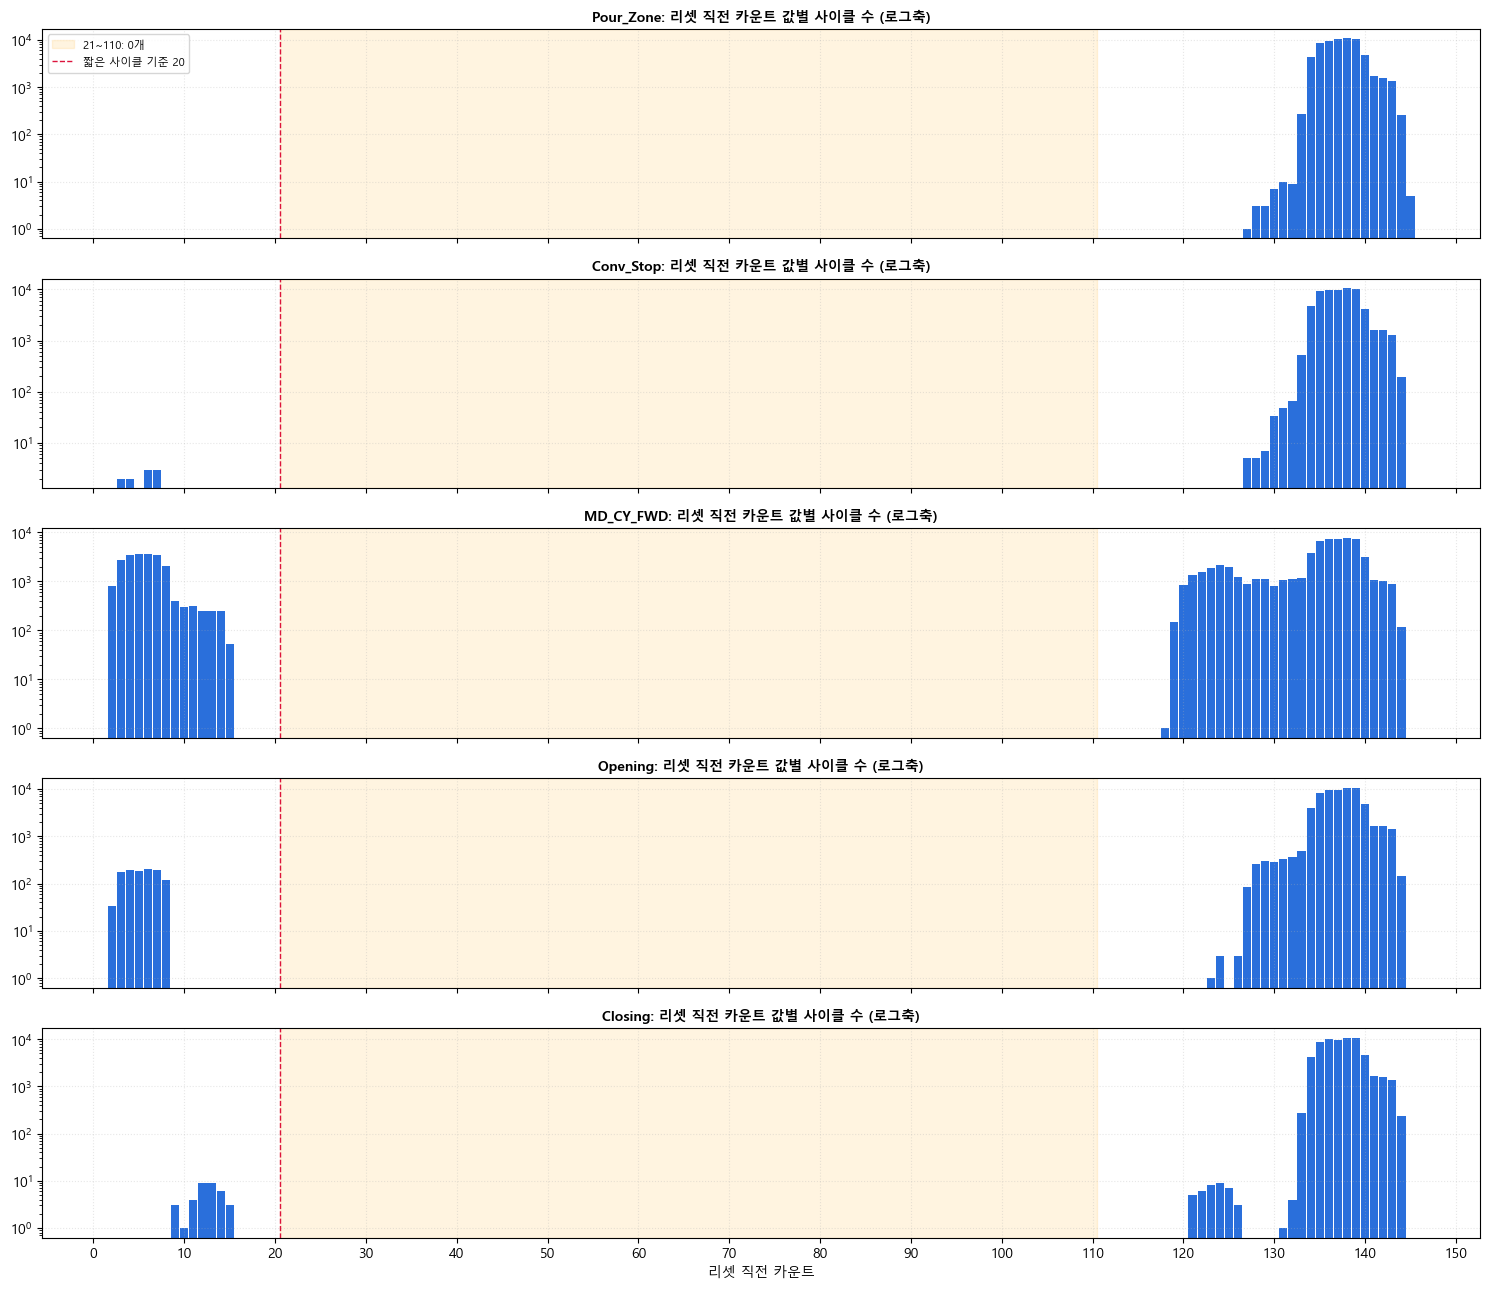

In [6]:
bins = list(range(0, 151, 10)); labels = [f"{a + 1}~{a + 10}" for a in bins[:-1]]
band = pd.DataFrame({n: pd.cut(CY[n].loc[CY[n]["clean"], "cnt_max"], bins, labels=labels).value_counts().reindex(labels)
                     for n in NAMES})
band.loc["합계"] = band.sum()
display(band)
for n in NAMES:
    value_table(CY[n]).to_csv(f"{OUT}/values_{n}.csv", encoding="utf-8-sig")

fig, axes = plt.subplots(len(NAMES), 1, figsize=(15, 2.6 * len(NAMES)), sharex=True)
for ax, n in zip(axes, NAMES):
    v = CY[n].loc[CY[n]["clean"], "cnt_max"].value_counts().sort_index()
    ax.bar(v.index, v.values, width=0.9, color="#2a6fdb"); ax.set_yscale("log")
    ax.axvspan(20.5, 110.5, color="orange", alpha=0.12, label="21~110: 0개")
    ax.axvline(20.5, color="crimson", ls="--", lw=1, label="짧은 사이클 기준 20")
    ax.set_title(f"{n}: 리셋 직전 카운트 값별 사이클 수 (로그축)", fontweight="bold", fontsize=10); ax.grid(alpha=0.3, ls=":")
axes[0].legend(fontsize=8); axes[-1].set_xlabel("리셋 직전 카운트"); axes[-1].set_xticks(range(0, 151, 10))
plt.tight_layout(); plt.show()

**짧은 사이클 기준을 20 으로 둔 근거**
- 다섯 카운터 모두 **21~110 구간이 0개**다. 리셋 직전 카운트는 **1~20 그룹**과 **111~150 그룹**으로 완전히 갈라진다.
- 짧은 그룹은 MD_CY_FWD 1~15, Opening 2~8, Closing 9~15, Conv_Stop 2~7 이고, 정상 그룹은 118 이상부터다.
- 그래서 기준을 20 이 아니라 30·50·100 으로 바꿔도 결과가 같다. 20 은 빈 구간 안의 한 값일 뿐이다.
- 정상 그룹 안에서 MD_CY_FWD 111~130 이 많은 것은, 두 번 감지로 **일찍 끊긴 앞 사이클**이 이 구간에 몰리기 때문이다(7-1, 7-2).
- 정상 그룹의 중심은 131~140 이다. 한 샘플(0.5초)에 카운트가 5~6씩 오르므로, 표준편차 2.2 중 약 1.6 은 샘플링 해상도에서 생긴다.

### 4-3. 짧은 사이클 안에서만 보이는 '멈춘 것 같은 값'
컨베이어가 움직이는 중이면 카운트는 한 샘플에 5~6씩 올라야 한다. 그런데 값이 그대로인 샘플(예: `8 → 5 → 5 → 11` 의 5, 5)이 있다.
그 사이에 리셋이 한 번 더 일어나 0 부터 다시 세어 같은 값이 찍힌 것으로 추정된다(DB 에 안 보인 리셋).

In [7]:
flat_rows = {}
for n in NAMES:
    cnt = COUNTERS[n][0]; df = RAW[n][~RAW[n].index.duplicated()]
    x = df[cnt]; d = x.diff(); dt = df.index.to_series().diff().dt.total_seconds()
    moving = (df[RUN] == 1) & (df[RUN_WARN] == 1) & (df[WARN_TIME] == 30) & (dt < 0.9)
    flat = moving & (d == 0) & (d.shift(1) > 0) & (d.shift(-1) > 0)
    flat_rows[n] = {"움직이는 중 값 그대로": int(flat.sum()), "그중 카운트 ≤20": int((flat & (x <= 20)).sum()),
                    "그중 카운트 >20": int((flat & (x > 20)).sum())}
pd.DataFrame(flat_rows).T

,움직이는 중 값 그대로,그중 카운트 ≤20,그중 카운트 >20
Pour_Zone,0,0,0
Conv_Stop,1,1,0
MD_CY_FWD,853,853,0
Opening,81,81,0
Closing,0,0,0


- 값이 그대로인 샘플은 **카운트 20 이하(리셋 직후)에서만** 나온다. 정상적으로 세는 구간(20 초과)에서는 0 이다.
- MD_CY_FWD 853 회, Opening 81 회 → 7-1 의 '합 부족(숨은 리셋 추정)'을 뒷받침하는 정황이다(직접 증거는 아님).

### 최소·최대가 나온 시각 (main 사이클)

In [8]:
for n in NAMES:
    lo, hi = extreme_cycles(CY[n], 5)
    print(f"── {n}"); display(pd.concat([lo.assign(kind="min"), hi.assign(kind="max")]))

── Pour_Zone


,end_time,cnt_max,duration_s,end_dt,k_clean,kind
22914,2026-09-15 22:56:39.655154,127.0,11.453172,0.531528,164,min
21039,2026-09-15 15:15:29.053277,128.0,11.479336,0.530652,439,min
22704,2026-09-15 21:59:04.230611,128.0,11.507586,0.541200,466,min
22872,2026-09-15 22:47:36.366266,128.0,11.466646,0.514422,122,min
22047,2026-09-15 19:11:02.075830,129.0,11.603030,0.512134,419,min
17828,2026-09-14 18:57:26.935673,145.0,13.140459,0.536359,301,max
17870,2026-09-14 19:06:39.827531,145.0,13.140085,0.546758,343,max
20998,2026-09-15 15:06:35.860896,145.0,13.111012,0.522762,398,max
22214,2026-09-15 20:10:37.180419,145.0,13.022213,0.519414,49,max
23041,2026-09-15 23:24:03.128946,145.0,13.087978,0.513494,291,max


── Conv_Stop


,end_time,cnt_max,duration_s,end_dt,k_clean,kind
22290,2026-09-15 20:28:32.135739,127.0,11.476233,0.579095,47,min
24896,2026-09-16 13:04:48.106231,127.0,11.927252,0.525720,435,min
42263,2026-09-21 11:36:54.726459,127.0,11.487183,0.532997,31,min
22051,2026-09-15 19:11:03.607798,128.0,11.541129,0.504223,420,min
31562,2026-09-17 22:56:38.582984,128.0,11.595767,0.533846,168,min
667,2026-09-09 22:00:07.671052,144.0,13.062779,0.539542,507,max
709,2026-09-09 22:21:10.076095,144.0,13.052708,0.522906,3,max
833,2026-09-09 22:48:13.547144,144.0,13.002457,0.482700,127,max
956,2026-09-09 23:15:01.779995,144.0,13.047185,0.561472,250,max
2553,2026-09-10 11:36:49.287240,144.0,13.064939,0.509954,31,max


── MD_CY_FWD


,end_time,cnt_max,duration_s,end_dt,k_clean,kind
1968,2026-09-10 06:53:03.324603,121.0,11.082770,0.527628,16,min
91921,2026-10-01 11:42:59.289850,122.0,14.217407,0.552425,85,min
3705,2026-09-10 12:03:12.957076,123.0,11.374052,0.525615,208,min
4581,2026-09-10 14:31:38.645590,123.0,11.471579,0.509230,331,min
9684,2026-09-11 11:31:17.844227,123.0,11.496372,0.537738,9,min
2471,2026-09-10 08:12:36.005262,144.0,16.217945,0.555420,267,max
4090,2026-09-10 13:03:46.920013,144.0,16.208333,0.540792,593,max
4150,2026-09-10 13:12:52.948276,144.0,16.115306,0.547445,653,max
4615,2026-09-10 14:37:36.742427,144.0,16.250319,0.541823,365,max
5486,2026-09-10 17:01:18.856657,144.0,14.094285,0.521228,575,max


── Opening


,end_time,cnt_max,duration_s,end_dt,k_clean,kind
21749,2026-09-15 16:09:46.056909,123.0,12.421573,0.188861,185,min
15981,2026-09-14 09:50:50.921598,127.0,11.441067,0.522355,237,min
35298,2026-09-18 16:43:51.642730,127.0,11.477952,0.516486,352,min
50668,2026-09-22 23:13:41.715444,127.0,11.505438,0.514340,249,min
51648,2026-09-23 08:37:35.096684,127.0,11.458609,0.536756,317,min
21,2026-09-09 19:04:56.291877,144.0,14.481687,0.478438,22,max
232,2026-09-09 20:24:02.114018,144.0,14.227013,0.518204,68,max
1733,2026-09-10 07:53:52.767875,144.0,14.656406,0.543968,110,max
1866,2026-09-10 08:22:21.509921,144.0,13.035280,0.518691,243,max
2036,2026-09-10 09:09:46.523545,144.0,14.096337,0.532125,44,max


── Closing


,end_time,cnt_max,duration_s,end_dt,k_clean,kind
83225,2026-10-05 14:32:17.759965,131.0,15.268640,0.172154,23,min
23644,2026-09-16 07:48:45.149133,132.0,15.059848,0.523449,87,min
27651,2026-09-17 06:33:57.691961,132.0,15.118432,0.518597,12,min
28952,2026-09-17 12:10:37.782053,132.0,15.178167,0.526859,151,min
74620,2026-10-02 15:59:17.463048,132.0,12.411250,0.837825,133,min
78,2026-09-09 19:17:25.776367,144.0,14.442267,0.516601,79,max
164,2026-09-09 20:10:23.709450,144.0,14.119556,0.530913,4,max
372,2026-09-09 20:55:45.473356,144.0,13.067193,0.515369,212,max
456,2026-09-09 21:14:04.960302,144.0,12.950502,0.515008,296,max
584,2026-09-09 21:42:01.167469,144.0,14.113328,0.511479,424,max


**9/15 오후~자정**에 낮은 값이 몰린다. Pour_Zone 최저 10개가 모두 9/15 15:15~9/16 00:00 이고, 같은 시각 Conv_Stop 도 낮다(1~2초 차).
두 카운터가 동시에 낮으면 센서 하나보다 대차 간격·벨트 쪽 원인일 가능성이 크다(원인 미확인).

## 5. 날짜별·시간대별 차이 — 거의 없음

,clean_n,double_n,double_pct,n,dur_med,dur_p90,max_mean,max_std,max_min,max_max
date,,,,,,,,,,
2026-09-09,1042,0,0.0,1042,12.58,14.60,137.39,2.10,133.0,144.0
2026-09-10,4072,0,0.0,4072,12.56,15.46,137.49,2.12,133.0,144.0
2026-09-11,4040,0,0.0,4040,12.55,15.04,137.43,2.13,133.0,144.0
2026-09-14,3908,0,0.0,3908,12.56,15.62,137.47,2.16,132.0,145.0
2026-09-15,4004,0,0.0,4004,12.56,15.49,137.45,2.26,127.0,145.0
2026-09-16,3990,0,0.0,3990,12.57,15.59,137.52,2.15,133.0,144.0
2026-09-17,3921,0,0.0,3921,12.56,15.58,137.50,2.18,133.0,144.0
2026-09-18,4027,0,0.0,4027,12.56,14.09,137.43,2.21,130.0,144.0
2026-09-21,4170,0,0.0,4170,12.56,15.54,137.47,2.19,133.0,144.0


,clean_n,double_n,double_pct,n,dur_med,dur_p90,max_mean,max_std,max_min,max_max
hour,,,,,,,,,,
0,147,0,0.0,147,12.57,15.56,137.47,2.11,133.0,143.0
1,18,0,0.0,18,12.56,13.42,137.78,2.67,134.0,142.0
4,8,0,0.0,8,12.57,13.08,139.25,2.38,136.0,143.0
5,586,0,0.0,586,12.56,15.37,137.45,2.09,133.0,144.0
6,2749,0,0.0,2749,12.56,15.24,137.45,2.15,131.0,144.0
7,2181,0,0.0,2181,12.56,15.54,137.48,2.18,130.0,144.0
8,3513,0,0.0,3513,12.56,15.53,137.49,2.16,133.0,144.0
9,4363,0,0.0,4363,12.56,15.55,137.44,2.12,130.0,144.0
10,3603,0,0.0,3603,12.56,15.55,137.42,2.18,133.0,144.0


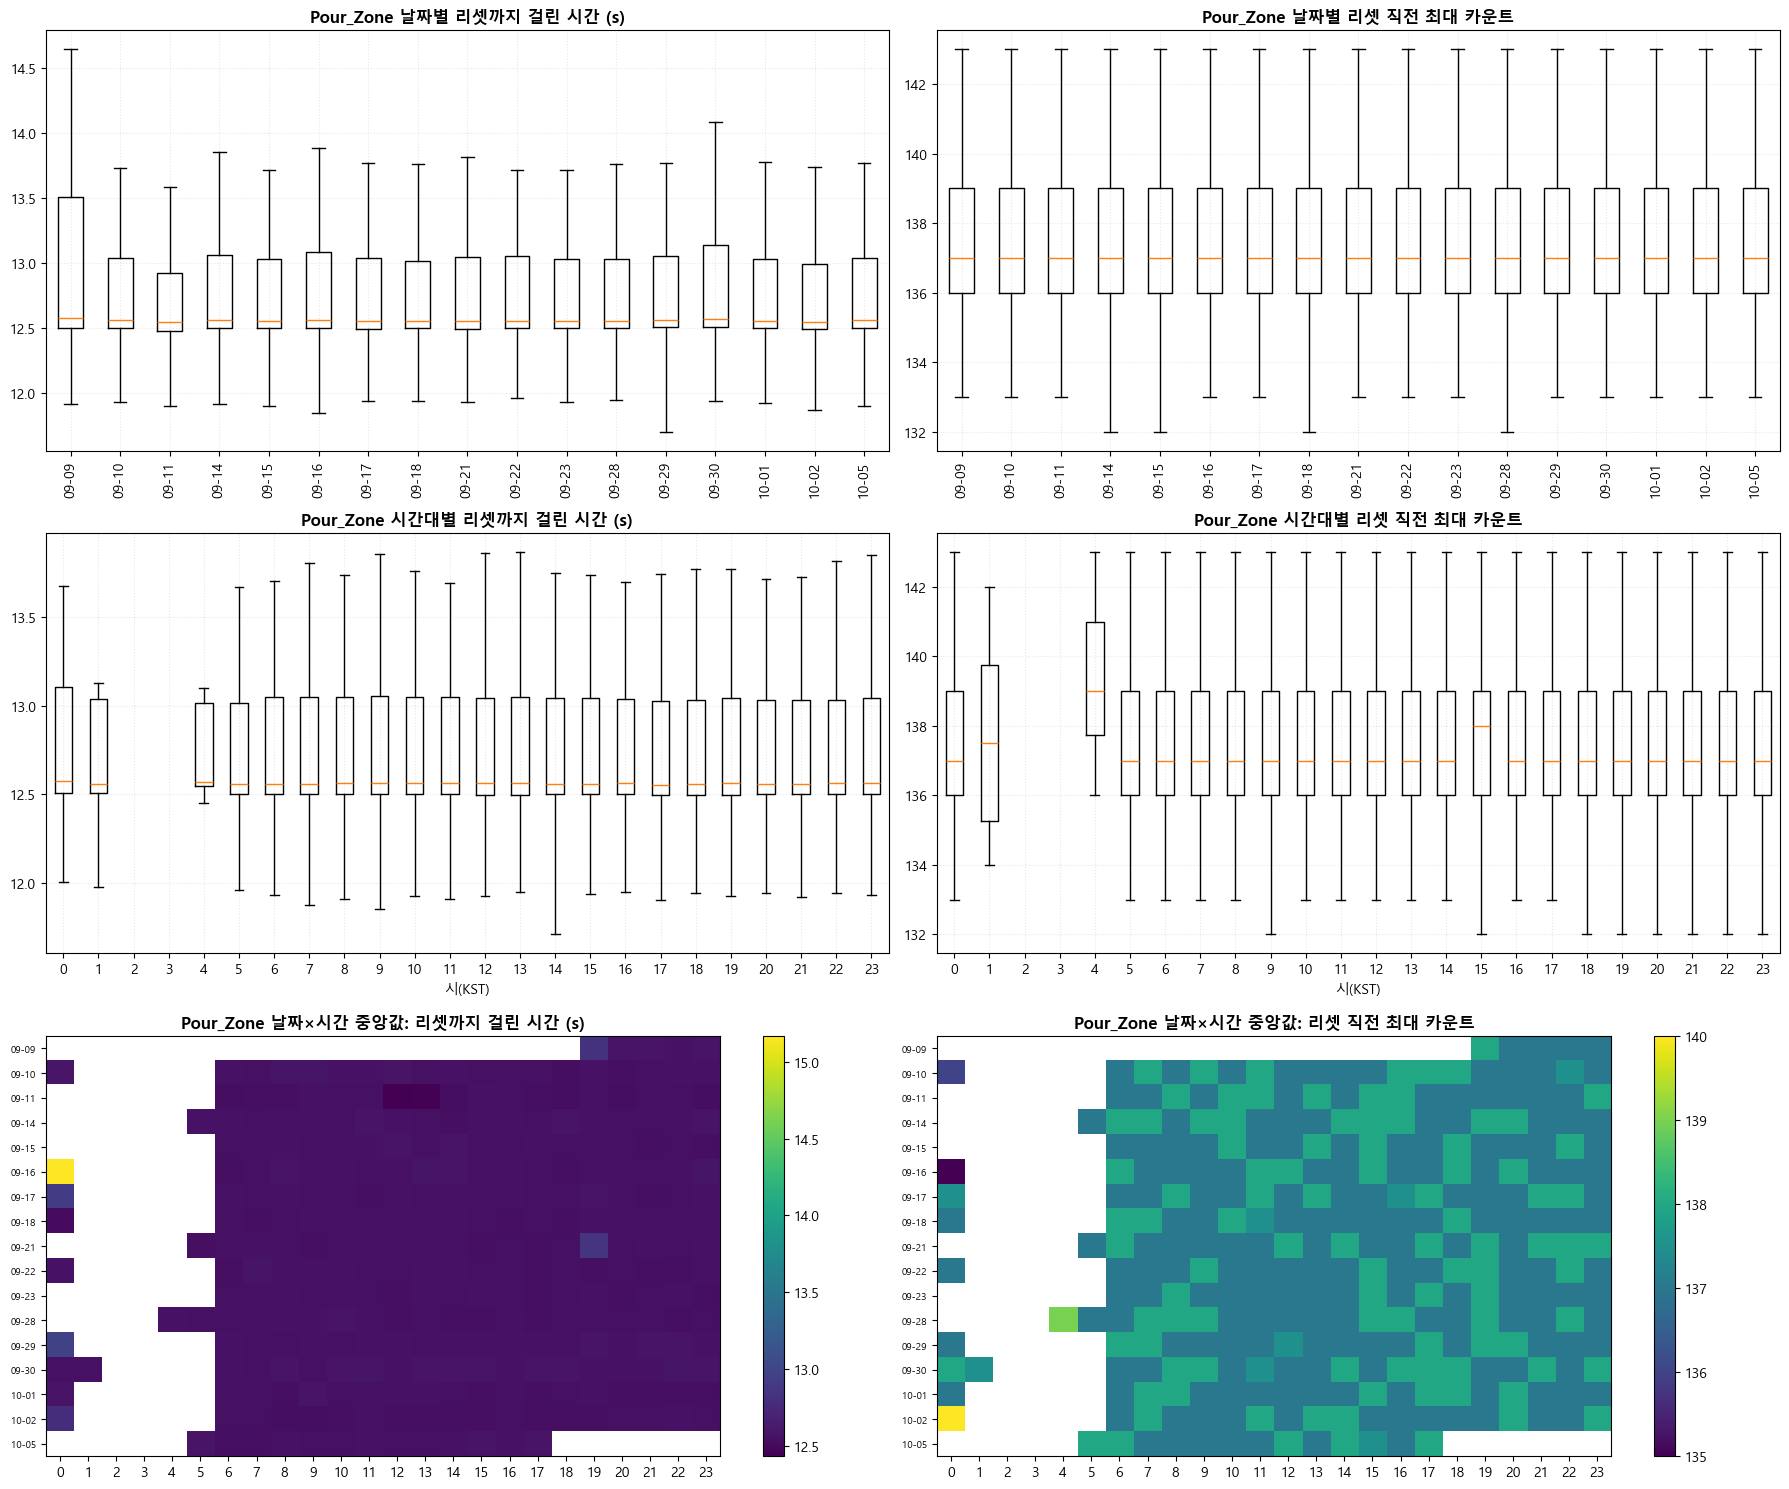

In [9]:
gd = {n: group_stats(CY[n], "date") for n in NAMES}
gh = {n: group_stats(CY[n], "hour") for n in NAMES}
display(gd["Pour_Zone"].round(2)); display(gh["Pour_Zone"].round(2))
for n in NAMES:
    gd[n].to_csv(f"{OUT}/by_date_{n}.csv", encoding="utf-8-sig"); gh[n].to_csv(f"{OUT}/by_hour_{n}.csv", encoding="utf-8-sig")
plot_by_date_hour(CY["Pour_Zone"], "Pour_Zone"); plt.show()

- 날짜별·시간대별 평균 137.4~137.6 으로 같다. 1시·4시가 달라 보이는 건 사이클 수가 8~27개뿐이라서다(평균에 영향 없음).
- 02~04시는 거의 비가동이다.

### 5-1. 사출 시작(07:00, 23:50)과 점심·저녁 시간은 다른가?
먼저 휴식 시간을 데이터로 찾는다 — 평일에 **5분 이상 정지**가 시작된 시각(10분 단위)과 재가동 시각.

In [10]:
stops = extract_stop_events(raw_pour, RS["Pour_Zone"])          # 6장에서도 쓴다
wk = stops[~is_off_day(stops["stop_time"])]
lg = wk[wk["stopped_s"] >= 300].copy()
lg["정지 시각"] = lg["stop_time"].dt.floor("10min").dt.strftime("%H:%M")
lg["재가동 시각"] = lg["restart_time"].dt.floor("10min").dt.strftime("%H:%M")
sched = lg.groupby("정지 시각").agg(횟수=("stopped_s", "size"), 날수=("stop_time", lambda x: x.dt.date.nunique()),
                                   정지_중앙_분=("stopped_s", lambda x: round(x.median() / 60, 1)),
                                   주요_재가동=("재가동 시각", lambda x: x.mode().iloc[0]))
sched[sched["횟수"] >= 7].sort_index()

,횟수,날수,정지_중앙_분,주요_재가동
정지 시각,,,,
00:00,7,6,6.6,00:10
00:10,11,11,6.7,00:20
00:20,10,10,8.1,00:30
08:40,16,16,12.2,09:00
10:50,12,11,5.8,11:00
11:00,14,12,11.3,11:10
11:10,7,7,15.1,11:20
13:20,15,15,12.4,13:40
15:20,16,16,7.3,15:30


평일 정지 일정(가동일 17일 중 대부분 같은 시각):

| 구분 | 정지 | 재가동 |
|---|---|---|
| 휴식 | 08:40 | 09:00 |
| 점심 | 10:50~11:10 | 11:00~11:20 |
| 휴식 | 13:20 | 13:40 |
| 휴식 | 15:20 | 15:30 |
| 휴식 | 17:20 | 17:40 |
| 저녁 | 19:20~19:50 | 19:30~19:50 |
| 휴식 | 22:00 | 22:20 |
| 야간 정지 | 00:00~00:20 | 다음날 06:10~06:30 |

정지 그 자체는 `has_stop` 으로 이미 빠진다. 아래는 07:00·23:50 전후를 10분 단위로 쪼개서, 사출 시작이 카운트에 영향을 주는지 본다
(시간대 제외를 하기 전 기준: 정지·끊김·알람·휴일·두 번 감지만 뺀 사이클).

In [11]:
slots = ["06:30", "06:40", "06:50", "07:00", "07:10", "07:20", "07:30", "07:40", "07:50",
         "23:20", "23:30", "23:40", "23:50", "00:00", "00:10", "00:20"]
base_ok = {n: ~(CY[n].has_gap | CY[n].end_gap | CY[n].has_stop | CY[n].has_alarm | CY[n].off_day) for n in NAMES}
tod_rows = {}
for n in NAMES:
    cy = CY[n].assign(tod=CY[n]["end_time"].dt.floor("10min").dt.strftime("%H:%M"))
    m = cy[base_ok[n] & ~cy["split"]]; c = cy[base_ok[n]]
    t = m.groupby("tod")["cnt_max"].agg(["size", "mean"]).join(c.groupby("tod")["short"].mean().mul(100).rename("dbl%"))
    tod_rows[n] = t.reindex(slots)
pd.concat(tod_rows, axis=1).round(2)

Pour_Zone              Conv_Stop               MD_CY_FWD                Opening               Closing              
           size    mean dbl%      size    mean  dbl%      size    mean   dbl%    size    mean  dbl%    size    mean  dbl%
tod                                                                                                                      
06:30       649  137.38  0.0       649  137.36  0.00       372  136.98  25.51     631  137.35  1.65     644  137.51  0.46
06:40       731  137.46  0.0       727  137.31  0.00       425  136.81  24.72     703  137.38  1.75     723  137.46  0.27
06:50       718  137.51  0.0       718  137.46  0.00       431  136.89  24.79     691  137.43  1.52     715  137.48  0.14
07:00       702  137.41  0.0       703  137.29  0.00       387  136.99  26.60     679  137.47  1.54     699  137.43  0.28
07:10       714  137.40  0.0       713  137.39  0.00       412  137.02  25.88     696  137.43  1.64     711  137.32  0.14
07:20       712  137.44  0.0       713  137.47  0.14       414  136.83  25.18     691  137.48  1.79     712  137.42  0.14
07:30       730  137.51  0.0       723  137.50  0.00       428  137.12  25.31     702  137.31  1.50     721  137.56  0.14
07:40       734  137.51  0.0       735  137.48  0.00       417  137.04  25.61     705  137.38  1.88     732  137.41  0.27
07:50       733  137.47  0.0       734  137.34  0.00       418  137.05  24.77     709  137.29  1.99     732  137.48  0.27
23:20       699  137.47  0.0       698  137.35  0.14       401  136.94  25.21     675  137.39  1.96     700  137.60  0.00
23:30       691  137.38  0.0       693  137.35  0.00       399  137.03  25.22     667  137.37  1.71     693  137.48  0.00
23:40       689  137.43  0.0       691  137.37  0.00       387  136.81  25.49     658  137.47  2.00     691  137.38  0.00
23:50       692  137.51  0.0       686  137.28  0.15       396  136.86  25.64     671  137.41  1.56     689  137.47  0.00
00:00       300  137.24  0.0       301  137.34  0.00       177  137.15  25.43     291  137.54  2.24     300  137.38  0.00
00:10       114  137.38  0.0       109  137.53  0.00        77  136.55  19.86     110  137.55  3.31     106  137.42  0.92
00:20        42  137.64  0.0        42  137.74  0.00        22  137.68  32.26      46  138.39  0.00      42  137.71  0.00

In [12]:
cmp = []
for n in NAMES:
    cy = CY[n]; b = base_ok[n] & ~cy["split"]; w = cy["tod_window"]
    row = {"카운터": n, "제외 전 평균": cy.loc[b, "cnt_max"].mean(), "제외 전 표준편차": cy.loc[b, "cnt_max"].std(),
           "제외 후 평균": cy.loc[b & (w == ""), "cnt_max"].mean(), "제외 후 표준편차": cy.loc[b & (w == ""), "cnt_max"].std(),
           "제외된 사이클": int((b & (w != "")).sum())}
    for name in EXCLUDE_TOD:
        row[f"{name} 평균"] = cy.loc[b & (w == name), "cnt_max"].mean()
    cmp.append(row)
pd.DataFrame(cmp).set_index("카운터").round(2)

,제외 전 평균,제외 전 표준편차,제외 후 평균,제외 후 표준편차,제외된 사이클,사출 시작(주간) 평균,사출 시작(야간) 평균,점심 평균,저녁 평균
카운터,,,,,,,,,
Pour_Zone,137.46,2.16,137.46,2.16,5150,137.43,137.42,137.67,137.43
Conv_Stop,137.34,2.19,137.34,2.19,5125,137.39,137.32,137.51,137.39
MD_CY_FWD,136.94,2.44,136.93,2.44,3000,136.96,136.90,136.94,136.96
Opening,137.41,2.27,137.41,2.28,5019,137.46,137.46,137.27,137.30
Closing,137.45,2.15,137.45,2.15,5119,137.40,137.44,137.62,137.49


**결과**
- 07:00·23:50 전후 10분 단위 평균은 다섯 카운터 모두 전체 평균과 **±0.2 안**이고, 두 번 감지율도 같다. 사출 시작의 영향은 보이지 않는다.
- 시간대를 빼기 전과 뺀 뒤의 평균·표준편차도 같다. 점심·저녁 전후도 마찬가지다.
- 그래도 요청대로 **사출 시작 30분(07:00~07:30, 23:50~00:20)과 점심(10:50~11:30)·저녁(19:20~20:00)은 기본으로 뺀다**(`EXCLUDE_TOD`, 끄려면 `drop_tod=False`).
  30분은 데이터로 정한 값이 아니다 — 차이가 없어서 정할 근거가 없었고, 보수적으로 잡은 값이다.
- 예외: **Closing 두 번 감지는 이른 아침(06:30~07:00)에 0.3~0.5% 로 평소(0.06%)보다 높다.** 9/16·9/28 아침 이벤트 때문이다.

## 6. 정지 시작 분석 (Pour_Zone)
- `Conv_Run_Warning` 1→0 이 정지 시작이다. 그 뒤 카운트 증가폭이 6→6→5→2→1 로 줄며 약 1초 감속 후 멈춘다.
- `Conv_Warning_Time` 은 정상 30, 정지 중 0, 재가동 때 약 3초간 0→30. 재가동 때도 30 이 아니므로 이것만으로는 정지 시작을 못 가른다.
- 재가동 램프 중 Run_Warning 이 0 으로 깜빡이는 것은 카운트가 안 움직이므로 정지 시작에서 뺀다.

정지 시작 474건 | 카운트 ≤20 에서 시작한 비율 30.0% (무작위라면 14.6%) | KS p = 3.0e-28
감속량 중앙 11.0 카운트, 정지 시간 중앙 338초


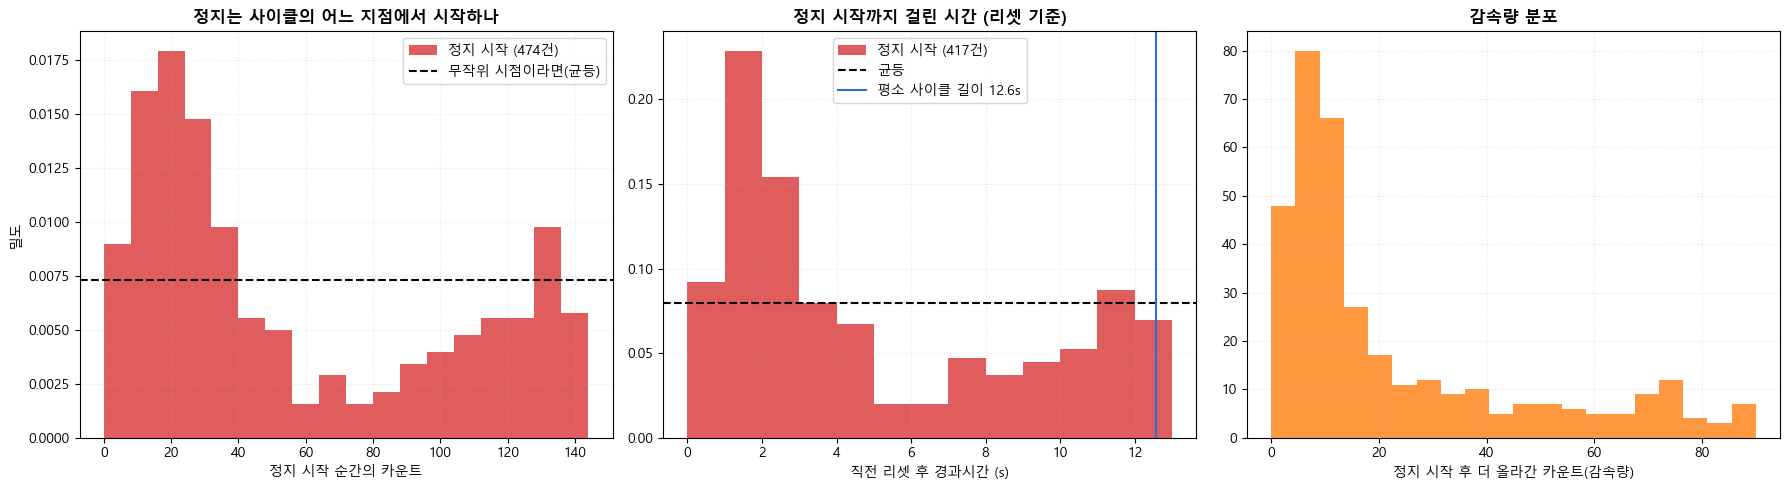

In [13]:
top = CY["Pour_Zone"].loc[CY["Pour_Zone"]["main"], "cnt_max"].median()
from scipy import stats
print(f"정지 시작 {len(stops)}건 | 카운트 ≤20 에서 시작한 비율 {(stops.cnt_at_stop <= 20).mean():.1%} (무작위라면 {20/top:.1%})"
      f" | KS p = {stats.kstest(np.clip(stops.cnt_at_stop / top, 0, 1), 'uniform').pvalue:.1e}")
print(f"감속량 중앙 {stops.cnt_coast.median()} 카운트, 정지 시간 중앙 {stops.stopped_s.median():.0f}초")
stops.to_csv(f"{OUT}/stop_events.csv", index=False, encoding="utf-8-sig")
plot_stop_start(stops, CY["Pour_Zone"]); plt.show()

정지는 사이클 앞쪽(리셋 후 1~3초, 카운트 10~40)에 몰린다 — 무작위 시점이 아니다. 정지가 낀 사이클도 리셋 직전 카운트는 정상(137.7)이다(정지 중 카운트가 멈춰 있으므로). 틀어지는 건 소요시간뿐이다.

## 7. 두 번 감지 정리

**현상**: 대차 한 대가 지날 때 센서가 **약 0.5초 간격으로 두 번** 켜져 리셋이 두 번 난다.

**모양** (Opening·Closing): 센서가 진짜 위치보다 *먼저* 한 번 켜진다 → 그 사이클이 일찍 끊김(Opening 중앙 130, Closing 124) →
0.5초 뒤 진짜 위치에서 다시 리셋 → 그 사이 카운트 5~13 짜리 짧은 사이클 → **다음 사이클은 정상**(137~138).

**전체 카운트에 영향이 쌓이나?** 아니다. 두 번째 리셋이 진짜 위치에서 다시 0 으로 맞추므로 오차가 다음 대차로 넘어가지 않는다.
끊긴 사이클 + 짧은 사이클 = 중앙 136 ≈ 정상 137 (모자란 1 은 샘플링으로 리셋 직전 몇 카운트를 못 본 몫).
다만 첫 리셋 ~ 두 번째 리셋 사이 약 0.5초 동안은 카운터가 실제보다 작은 값을 보인다 → PLC 가 이 카운트로 다른 동작을 건다면 그 순간 영향이 있을 수 있다.

**MD_CY_FWD** 는 짧은 사이클이 2개 연속(세 번 감지)인 경우가 많고, 합 중앙 133 으로 약간 더 모자란다.

In [14]:
rows = []
for n in NAMES:
    cy = CY[n].reset_index(drop=True); s = cy["short"].values; v = cy["cnt_max"].values; cl = cy["clean"].values
    sums, runs, prev = [], [], []
    i = 1
    while i < len(cy):
        if s[i] and not s[i - 1]:
            j = i
            while j < len(cy) and s[j]: j += 1
            if cl[i - 1:j].all() and j < len(cy):
                sums.append(v[i - 1:j].sum()); runs.append(j - i); prev.append(v[i - 1])
            i = j
        else:
            i += 1
    sums = pd.Series(sums, dtype=float)
    rows.append({"counter": n, "clean 사이클": int(cy["clean"].sum()), "두 번 감지(짧은 사이클)": int(cy.loc[cy.clean, "short"].sum()),
                 "비율 %": cy.loc[cy.clean, "short"].mean() * 100, "묶음 수": len(sums),
                 "세 번 이상 감지 묶음": int((pd.Series(runs) >= 2).sum()) if runs else 0,
                 "끊긴 앞 사이클 중앙": pd.Series(prev).median() if prev else np.nan,
                 "앞+짧은 합 중앙": sums.median() if len(sums) else np.nan})
double_tbl = pd.DataFrame(rows).set_index("counter").round(2)
double_tbl

,clean 사이클,두 번 감지(짧은 사이클),비율 %,묶음 수,세 번 이상 감지 묶음,끊긴 앞 사이클 중앙,앞+짧은 합 중앙
counter,,,,,,,
Pour_Zone,64241,0,0.00,0,0,NaN,NaN
Conv_Stop,64209,10,0.02,10,0,129.5,134.0
MD_CY_FWD,85746,21490,25.06,14808,6596,124.0,133.0
Opening,65334,1109,1.70,1102,0,130.0,136.0
Closing,64241,35,0.05,35,0,123.0,136.0


### 7-1. 짧은 사이클(카운트 ≤20)은 모두 두 번 감지인가?

짧은 사이클을 **묶음** 단위로 본다. 묶음 = 연속된 짧은 사이클 + 바로 앞 사이클(일찍 끊긴 사이클).
센서가 여러 번 감지한 것이라면, 묶음의 카운트 합이 정상 한 사이클 거리(**128~146**)와 같아야 한다.

| 분류 | 조건 | 해석 |
|---|---|---|
| 두 번 감지 (합 정상) | 정상 운전, 짧은 사이클 1개, 합 128~146 | 확인됨 |
| 세 번 이상 감지 (합 정상) | 정상 운전, 짧은 사이클 2개 이상 연속, 합 128~146 | 확인됨 |
| 합 부족 (숨은 리셋 추정) | 정상 운전, 합 < 128 | 리셋 한 번에 못 보는 카운트는 최대 5~6 → 약 12 가 빠지려면 DB 에 안 보인 리셋이 하나 더 있어야 함 (**추정**) |
| 합 초과 | 정상 운전, 합 > 146 | 두 번 감지로 설명 안 됨 |
| 정지 중 감지 (합 정상) | 묶음 안에 정지·재가동 | 천천히 움직일 때 여러 번 감지 |
| 정지 중 (합 안 맞음) | 묶음 안에 정지·재가동, 합 범위 밖 | 정지 중 카운트가 멈춰 판단 어려움 |
| 수집 끊김 (판단 불가) | 묶음 안에 DB 누락 | 판단 불가 |

비율은 **짧은 사이클 수** 기준이고, 주말·추석도 포함한 전체 기간이다(분류는 통계가 아니라 사건 확인이므로).

In [15]:
SC = {n: classify_short_cycles(CY[n]) for n in NAMES}
cls_tbl = pd.concat({n: short_class_table(g) for n, g in SC.items() if len(g)}, axis=1)
tot = cls_tbl.xs("짧은 사이클", axis=1, level=1).sum()
confirmed = cls_tbl.xs("%", axis=1, level=1).loc[["두 번 감지 (합 정상)", "세 번 이상 감지 (합 정상)", "정지 중 감지 (합 정상)"]].sum()
print("짧은 사이클 전체:", tot.to_dict())
print("여러 번 감지로 확인된 비율 % (정상 운전 + 정지 중, 합 정상):", confirmed.round(1).to_dict())
for n, g in SC.items():
    g.to_csv(f"{OUT}/short_cycles_{n}.csv", index=False, encoding="utf-8-sig")
cls_tbl

짧은 사이클 전체: {'Conv_Stop': 19, 'MD_CY_FWD': 28077, 'Opening': 1535, 'Closing': 49}
여러 번 감지로 확인된 비율 % (정상 운전 + 정지 중, 합 정상): {'Conv_Stop': 100.0, 'MD_CY_FWD': 92.7, 'Opening': 99.9, 'Closing': 100.0}


Conv_Stop       MD_CY_FWD       Opening       Closing      
                    짧은 사이클     %    짧은 사이클     %  짧은 사이클     %  짧은 사이클     %
category                                                                    
두 번 감지 (합 정상)           17  89.5      9032  32.2    1502  97.9      41  83.7
세 번 이상 감지 (합 정상)         0   0.0     16682  59.4       0   0.0       0   0.0
합 부족 (숨은 리셋 추정)          0   0.0      1993   7.1       0   0.0       0   0.0
합 초과                     0   0.0         0   0.0       0   0.0       0   0.0
정지 중 감지 (합 정상)           2  10.5       315   1.1      31   2.0       8  16.3
정지 중 (합 안 맞음)            0   0.0        21   0.1       0   0.0       0   0.0
수집 끊김 (판단 불가)            0   0.0        34   0.1       2   0.1       0   0.0

**정리**
- **Pour_Zone**: 짧은 사이클 없음.
- **Conv_Stop / Opening / Closing**: 짧은 사이클 **100% 가 여러 번 감지로 설명된다**(Opening 은 수집 끊김 2개 = 0.1% 만 판단 불가).
  정상 운전 중이 84~98%, 나머지는 정지·재가동 중에 생겼다. 두 번 감지가 아닌 다른 원인(데이터 오류 등)으로 생긴 짧은 사이클은 없었다.
- **MD_CY_FWD**: 짧은 사이클 28,077개 중 **92.7%** 가 확인됨. 그중 *세 번 이상* 감지가 59.4% 로 *두 번*(32.2%)보다 많다.
  **7.1%(1,993개)는 합이 125~127 정도로 약 12 모자라는** '합 부족'이다 — 리셋이 DB 에 하나 덜 보인 세 번 감지로 추정하지만, 직접 확인한 것은 아니다.
  합 초과(설명 안 되는 경우)는 0건.
- 묶음별 상세(시각·합·분류)는 `conv_count_out/short_cycles_<카운터>.csv`.

### 7-2. 앞 + 짧은 사이클 합은 정상 사이클 카운트와 비슷한가?

7-1 은 합이 128~146 인지로 분류했으므로, 그 결과만 보면 '비슷하다'는 결론이 정해져 있다.
여기서는 **범위로 거르지 않고** 정상 운전·평일에 생긴 묶음 전체의 합을 정상(main) 사이클의 리셋 직전 카운트와 비교한다.

예상: 리셋이 한 번 더 생기면 0.5초 샘플 사이에서 못 본 카운트(0~6, 평균 약 3)만큼 합이 작아질 수 있다.

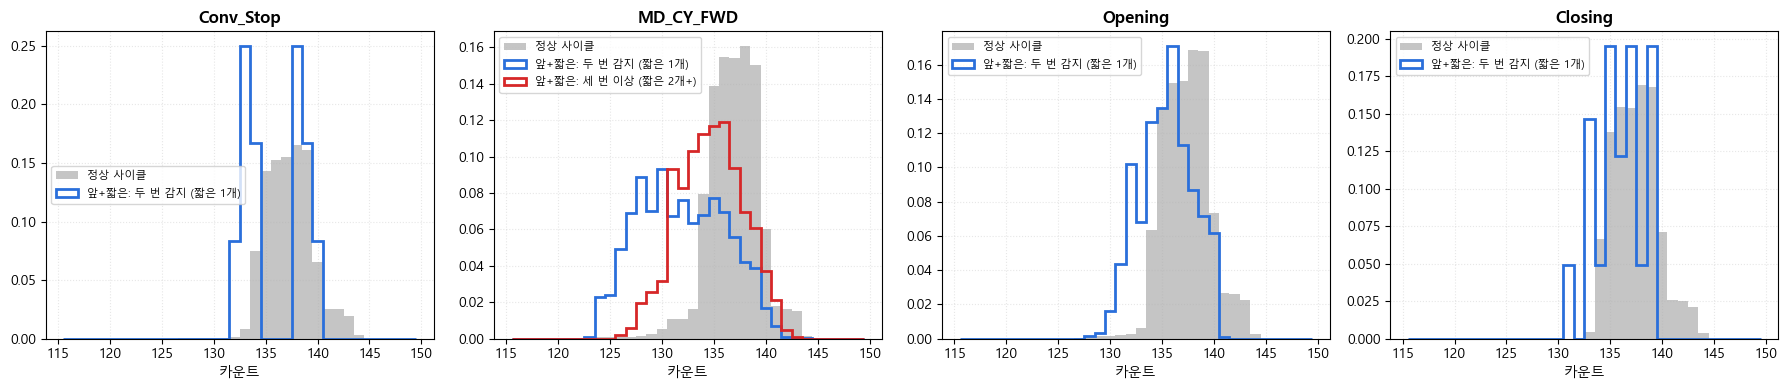

묶음 수    합 평균  합 표준편차   합 중앙   정상 평균  정상 표준편차  평균 차이 정상 99% 범위  범위 안 %
카운터       묶음                                                                                    
Conv_Stop 두 번 감지 (짧은 1개)     12  135.92    2.97  136.0  137.34     2.19  -1.42   133~143   91.67
MD_CY_FWD 두 번 감지 (짧은 1개)   8875  131.91    4.17  132.0  136.93     2.44  -5.03   129~143   74.52
          세 번 이상 (짧은 2개+)  7134  134.65    3.15  135.0  136.93     2.44  -2.28   129~143   97.25
Opening   두 번 감지 (짧은 1개)   1188  135.40    2.56  136.0  137.41     2.28  -2.01   130~143   99.49
Closing   두 번 감지 (짧은 1개)     41  135.90    2.28  136.0  137.45     2.15  -1.55   134~143   80.49

In [16]:
cmp_rows = []
fig, axes = plt.subplots(1, len(SC) - (0 if len(SC["Pour_Zone"]) else 1), figsize=(18, 4))
axes = iter(np.atleast_1d(axes))
for n, g in SC.items():
    if len(g) == 0:
        continue
    g = g[(g["situation"] == "정상 운전") & ~g["off_day"]]
    base = CY[n].loc[CY[n]["main"], "cnt_max"]
    lo, hi = base.quantile([0.005, 0.995])
    ax = next(axes)
    ax.hist(base, bins=np.arange(115.5, 150.5), density=True, alpha=0.45, color="gray", label="정상 사이클")
    for lab, sub, col in [("두 번 감지 (짧은 1개)", g[g["n_short"] == 1], "#2a6fdb"), ("세 번 이상 (짧은 2개+)", g[g["n_short"] >= 2], "#d62728")]:
        if len(sub) == 0:
            continue
        x = sub["sum"]
        cmp_rows.append({"카운터": n, "묶음": lab, "묶음 수": len(x), "합 평균": x.mean(), "합 표준편차": x.std(), "합 중앙": x.median(),
                         "정상 평균": base.mean(), "정상 표준편차": base.std(), "평균 차이": x.mean() - base.mean(),
                         "정상 99% 범위": f"{lo:.0f}~{hi:.0f}", "범위 안 %": x.between(lo, hi).mean() * 100})
        ax.hist(x, bins=np.arange(115.5, 150.5), density=True, histtype="step", lw=2, color=col, label=f"앞+짧은: {lab}")
    ax.set_title(n, fontweight="bold"); ax.set_xlabel("카운트"); ax.legend(fontsize=8); ax.grid(alpha=0.3, ls=":")
plt.tight_layout(); plt.show()
cmp_tbl = pd.DataFrame(cmp_rows).set_index(["카운터", "묶음"]).round(2)
cmp_tbl

**결과**
- **Conv_Stop / Opening / Closing**: 앞+짧은 합 평균이 정상보다 **1.4~2.0 작고**, 표준편차(2.3~3.0)는 정상(2.2~2.3)과 비슷하다.
  리셋이 한 번 더 생겨서 생기는 샘플링 손실 예상치(평균 약 3) 안이다 → **한 사이클 거리로 보기에 충분히 비슷하다.**
  정상 99% 범위 안 비율은 Opening 99%, Closing 80%, Conv_Stop 92%다. Closing·Conv_Stop 은 묶음이 41개·12개뿐이고, 평균이 1.5 낮아 범위 아래 끝(134, 133)에 걸리는 묶음이 있다.
- **MD_CY_FWD**:
  - 세 번 이상(짧은 2개+): 평균 **−2.3**, 범위 안 97% → 정상과 비슷하다.
  - 두 번(짧은 1개): 평균 **−5.0**, 범위 안 **75%** → 정상보다 확실히 작다. 7-1 의 '합 부족'(합 125~127)이 대부분 여기에 있다.
    DB 에 보이는 짧은 사이클은 1개지만 실제로는 샘플 사이에 리셋이 하나 더 있던 세 번 감지로 추정한다(직접 확인 불가).
- 정리하면, 짧은 사이클은 **일찍 끊긴 앞 사이클의 나머지**이고, 둘을 합치면 정상 한 사이클과 거의 같은 거리가 된다. MD_CY_FWD 는 감지가 더 잦아서 일부는 DB 로 다 보이지 않는다.

date,2026-09-09,2026-09-10,2026-09-11,2026-09-14,2026-09-15,2026-09-16,2026-09-17,2026-09-18,2026-09-21,2026-09-22,2026-09-23,2026-09-28,2026-09-29,2026-09-30,2026-10-01,2026-10-02,2026-10-05
Pour_Zone,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Conv_Stop,0,0,0,1,6,0,0,0,3,0,0,0,0,0,0,0,0
MD_CY_FWD,408,1563,1563,1325,1308,1307,1314,1244,1514,1308,1107,1279,1250,1346,1413,1562,679
Opening,23,95,97,84,106,95,112,106,87,37,33,35,18,14,55,74,38
Closing,0,0,0,0,0,24,0,0,0,0,0,11,0,0,0,0,0


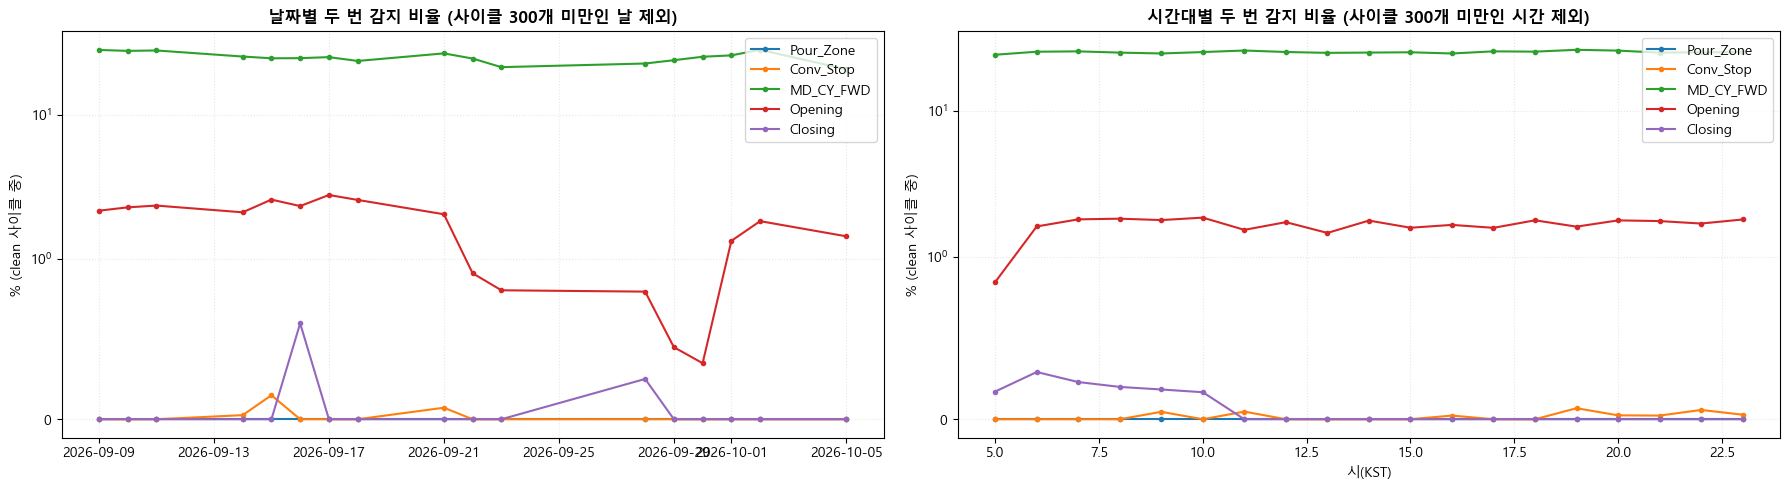

In [17]:
dd = pd.DataFrame({n: CY[n][CY[n]["clean"]].groupby("date")["short"].agg(["size", "sum"]).query("size >= 300")["sum"] for n in NAMES}).fillna(0).astype(int)
display(dd.T)
plot_double_detect({n: CY[n] for n in NAMES}); plt.show()

- **MD_CY_FWD**: 날짜·시간대 상관없이 늘 **21~28%** → 상시 문제. 기준선을 이 데이터로 잡으면 이 상태가 '정상'으로 학습되므로 **센서 점검이 먼저**다.
- **Opening**: 평소 약 2% → 9/22~9/30 0.4~0.9% 로 감소 → 10/1 부터 다시 1.3~2.2%. 9/22 무렵 정비·조정 이력 확인 필요.
- **Closing**: 9/16(29건), 9/28(12건) 오전 5~10시에만 발생.
- **Conv_Stop** 17건, **Pour_Zone** 0건.

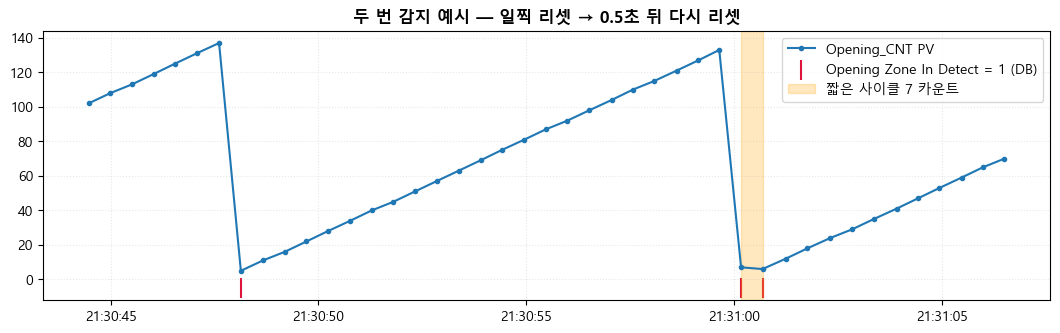

In [18]:
# 예시: Opening 두 번 감지 한 건의 원시 카운트
cy = CY["Opening"]; ex = cy[cy["short"] & cy["clean"]].iloc[10]
t0, t1 = ex.start_time - pd.Timedelta(seconds=16), ex.end_time + pd.Timedelta(seconds=6)
seg = raw_zone.loc[t0:t1]
fig, ax = plt.subplots(figsize=(13, 3.5))
ax.plot(seg.index, seg["Opening_CNT PV"], ".-", label="Opening_CNT PV")
on = seg[seg["Opening Zone In Detect"] != 0]
ax.scatter(on.index, np.zeros(len(on)) - 5, marker="|", s=200, color="crimson", label="Opening Zone In Detect = 1 (DB)")
ax.axvspan(ex.start_time, ex.end_time, color="orange", alpha=0.25, label=f"짧은 사이클 {ex.cnt_max:.0f} 카운트")
ax.set_title("두 번 감지 예시 — 일찍 리셋 → 0.5초 뒤 다시 리셋", fontweight="bold"); ax.legend(); ax.grid(alpha=0.3, ls=":")
plt.show()

## 8. 데이터 품질 — 신호 없는 리셋은 DB 누락
리셋 직전 샘플 간격은 리셋이 찍힌 행과 그 바로 앞 행의 시간 차다(정상 0.52초). 1.5초면 그 사이 샘플 2~3개가 DB 에 없다.

- Pour_Zone: 리셋 83,820건 중 DB 에 센서 신호가 없는 건 10건. 그중 9건이 리셋 직전 간격 > 0.9초.
- 존 감지 센서(Opening/Closing Zone In Detect 등)는 펄스가 짧아서, 리셋 순간 DB 에 보이는 비율이 55~75%뿐이다. → 이 비율은 센서 판단에도, 수집 품질 판단에도 쓰기 어렵다. Pour_Zone 의 TMON_SIG 만 쓸 만하다.

In [19]:
q = pd.DataFrame({n: {"리셋": len(RS[n]), "DB에 신호 없음": int(RS[n].sig_lost.sum()),
                      "그중 직전 간격>0.9s": int(RS[n].sig_lost_db_gap.sum()),
                      "신호 보인 비율 %": round((~RS[n].sig_lost).mean() * 100, 1)} for n in NAMES}).T
q

,리셋,DB에 신호 없음,그중 직전 간격>0.9s,신호 보인 비율 %
Pour_Zone,83820.0,10.0,9.0,100.0
Conv_Stop,83847.0,36990.0,27.0,55.9
MD_CY_FWD,111902.0,27526.0,11.0,75.4
Opening,85352.0,33356.0,21.0,60.9
Closing,83877.0,33630.0,24.0,59.9


## 9. 이상 판정 모델

**가능하다.** 정상 분포가 좁고(리셋 직전 카운트 137 ± 2.2) 날짜·시간대와 무관해서, 통계 기준선 + 규칙으로 충분하다.
고장 라벨이 없어서 ML(오토인코더 등)은 '얼마나 잘 잡는지'를 검증할 방법이 없고, 규칙보다 나은 점도 없다. 규칙은 이유를 설명할 수 있다는 장점도 있다.

| 규칙 | 등급 | 조건 | 기준값 산정 |
|---|---|---|---|
| `no_reset` | 오류 | 카운트가 `over_cnt` 초과 = 센서가 대차를 못 잡음 | 학습 최대 + 10 (≈154) |
| `cnt_shift` | 오류 | 최근 20 사이클 리셋 직전 카운트 **중앙값**이 범위 밖 = 감지 위치가 계속 틀어짐 | 학습 이동중앙값 min−1 ~ max+1 (≈134~141) |
| `cnt_single` | 경고 | 리셋 직전 카운트 1개가 범위 밖 | p0.05−3 ~ p99.95+3 |
| `dur_long` | 경고 | 정지 없이 리셋까지 너무 오래 | p99.9 × 1.25 (≈20초) |
| `dur_shift` | 경고 | 최근 20 사이클 소요시간 중앙값이 너무 김 | 학습 최대 + 1초 |
| `double` | 경고 | 최근 100 사이클 중 두 번 감지 수 | 중앙값 + max(2, 3√중앙값) |

소요시간은 컨베이어 속도 영향을 받으므로 경고까지만 둔다. 센서 판단의 중심은 **리셋 직전 카운트**다.

In [20]:
MODELS = {}
for n in NAMES:
    MODELS[n] = CounterHealthModel(n).fit(CY[n], RAW[n][COUNTERS[n][0]].max())
    MODELS[n].save(f"models/conv_health_{n}.json")
th = pd.DataFrame({n: m.th for n, m in MODELS.items()}).T
th[["over_cnt", "cnt_lo", "cnt_hi", "roll_lo", "roll_hi", "dur_hi", "roll_dur_hi", "dbl_median", "dbl_hi", "train_n"]]

,over_cnt,cnt_lo,cnt_hi,roll_lo,roll_hi,dur_hi,roll_dur_hi,dbl_median,dbl_hi,train_n
Pour_Zone,155.0,129.12,147.0,134.0,141.0,20.31,14.07,0.0,2.0,64241
Conv_Stop,154.0,127.0,147.0,133.5,141.0,20.04,14.13,0.0,2.0,64179
MD_CY_FWD,154.0,121.0,147.0,134.0,140.0,20.3,14.27,25.0,40.0,37503
Opening,154.0,125.0,147.0,134.0,141.0,20.12,15.09,2.0,6.242641,62025
Closing,154.0,130.0,147.0,134.0,141.0,19.71,14.12,0.0,2.0,64134


### 카운터별 기준 (위 표 요약)
- **Pour_Zone / Conv_Stop / Opening / Closing**: 정상 중앙 137. 20사이클 중앙값 **134~141 밖이면 오류**, 단일 값 **≈127~147 밖이면 경고**, 카운트 **≈154 초과면 오류(리셋 누락)**.
  두 번 감지는 평소 0 이라 **100 사이클 중 2건 이상이면 경고**(Opening 은 평소 2건이라 **7건 이상**).
- **MD_CY_FWD**: 카운트 기준은 같다. 두 번 감지는 평소 25건/100 이라 기준이 40건 — 이건 '정상'이 아니라 *이미 나쁜 상태를 기준으로 삼은 것*이므로 점검 후 다시 학습해야 한다.

### 9-1. 검증 ① 기간을 나눠 오탐 확인 — 9/9~9/26 학습, 9/28~10/5 시험

In [21]:
split = pd.Timestamp("2026-09-27"); val = []
for n in NAMES:
    cy = CY[n]; tr = cy[cy.end_time < split].reset_index(drop=True); te = cy[cy.end_time >= split].reset_index(drop=True)
    m = CounterHealthModel(n).fit(tr, tr.cnt_max.max())
    ev = m.events(m.score(te))
    val.append({"counter": n, "시험 가동일": te[te.main].date.nunique(), "시험 사이클": int(te.main.sum()),
                **{r: int((ev.rule == r).sum()) for r in CounterHealthModel.RULES}})
pd.DataFrame(val).set_index("counter")

,시험 가동일,시험 사이클,no_reset,cnt_shift,cnt_single,dur_long,dur_shift,double
counter,,,,,,,,
Pour_Zone,6,22970,0,0,0,0,0,0
Conv_Stop,6,22959,0,0,0,0,0,0
MD_CY_FWD,6,14080,0,0,0,0,0,0
Opening,6,22512,0,0,0,0,0,0
Closing,6,22943,0,0,0,0,0,5


시험 구간에서 Closing 의 `double` 5건(9/28 오전)만 나왔고, 이건 실제 두 번 감지 이벤트다. 나머지 규칙은 6일 동안 경보가 하나도 없었다.

### 9-2. 검증 ② 이상 주입 — 리셋 직전 카운트를 인위로 옮겼을 때 몇 사이클 만에 오류를 내나

In [22]:
inj = []
for n in NAMES:
    cy = CY[n]; tr = cy[cy.end_time < split].reset_index(drop=True); te = cy[cy.end_time >= split].reset_index(drop=True)
    m = CounterHealthModel(n).fit(tr, tr.cnt_max.max()); row = {"counter": n}
    for delta in (-5, -3, 3, 5):
        t2 = te.copy(); k0 = len(t2) // 2; t2.loc[k0:, "cnt_max"] += delta
        after = m.score(t2).loc[k0:]
        hit = after.index[after.cnt_shift]
        row[f"{delta:+d}"] = int(after.loc[:hit[0], "main"].sum()) if len(hit) else None
    inj.append(row)
pd.DataFrame(inj).set_index("counter")   # 값 = 첫 오류까지 main 사이클 수 (1 사이클 ≈ 12.6초)

,-5,-3,+3,+5
counter,,,,
Pour_Zone,12,61,30,16
Conv_Stop,11,42,66,16
MD_CY_FWD,13,17,46,16
Opening,12,23,40,10
Closing,10,12,286,21


- **±5 카운트**(감지 위치 약 4% 이동) → 10~21 사이클(약 2~4분) 안에 오류.
- **±3 카운트** → 12~286 사이클. 정상 흔들림(±2.2)과 겹쳐서 느리다. 더 빨리 잡으려면 W 를 키우거나 범위를 좁혀야 하는데, 그러면 오탐이 늘어난다.
- 실제 고장 사례가 아니라 *인위 주입*이라는 한계가 있다. 실제 센서 고장 날짜를 알면 그 구간으로 다시 검증해야 한다.

## 10. 실제 사용 예 — 새 데이터에 판정
- **사이클이 끝날 때마다(리셋 순간)** `score` → `cnt_shift`, `cnt_single`, `double`, `dur_*` 판정
- **매 틱** `현재 카운트 > over_cnt` → `no_reset`(센서가 아예 안 잡을 때는 사이클이 안 끝나므로 이걸로만 잡힌다)

In [23]:
n = "Pour_Zone"
m = CounterHealthModel.load(f"models/conv_health_{n}.json")
recent = raw_pour.loc["2026-10-05 10:00":]                     # 새로 받은 데이터라고 가정
cy_new, _ = extract_count_cycles(recent, *COUNTERS[n])
scored = m.score(cy_new)
print("사이클", len(scored), "| 오류", int(scored.error.sum()), "| 경고", int(scored.warning.sum()))
display(m.events(scored))
print("리셋 누락:", len(find_no_reset(recent, COUNTERS[n][0], m.th["over_cnt"])), "건")

사이클 1714 | 오류 0 | 경고 0


,rule,start,end,n_cycles


리셋 누락: 0 건


## 11. 정리
1. **센서 이상 지표** = 리셋 직전 카운트(중심), 두 번 감지 비율, 리셋 누락. 소요시간은 보조.
2. **데이터 품질 지표** = 신호 없는 리셋, 리셋 직전 샘플 간격. 센서 판단에 쓰지 않는다.
3. **바로 확인할 것**: MD_CY_FWD 두 번 감지 25%(상시) 점검, Opening 9/22 전후 변화 원인, Closing=Air_Bag 태그 매핑, 9/15 오후 카운트 저하 원인.
4. **남은 일**: 실제 센서 고장 날짜로 검증, MD_CY_FWD 점검 뒤 기준 재학습.